In [14]:
# Cell 0 — setup (frames_extraction.ipynb)
from pathlib import Path
import os, re, shutil, json
import pandas as pd
import numpy as np
import av
from PIL import Image
from tqdm.auto import tqdm

HOME     = Path.home()
ARCH     = HOME / "dataset_arch" / "SignLanguage"
WORK     = HOME / "work" / "signlanguage"
REPORTS  = WORK / "reports"
OUT_ROOT = ARCH / "frames_batch2_30fps"

TARGET_FPS = 30
SIZE       = 448      # output picture size
QUALITY    = 95       # JPEG quality

# the clip list made in checkin_clips.ipynb
rgb = pd.read_csv(REPORTS / "batch2_rgb.csv")

def clip_id(row):
    st  = "A" if "stationA" in row.station else "B"
    cat = int(re.match(r"^(\d+)", row.category).group(1))
    return f"b2_{st}_{cat:02d}_{int(row.id):04d}"

rgb["cid"]    = rgb.apply(clip_id, axis=1)
rgb["stride"] = (rgb.fps / TARGET_FPS).round().astype(int)

print(f"clips loaded   : {len(rgb)}")
print(f"unique clip ids: {rgb.cid.nunique()}   (must match)")
print(f"output folder  : {OUT_ROOT}")
print()
print(rgb[["cid", "station", "category", "id", "fps", "stride", "nb_frames"]].head(5).to_string(index=False))

clips loaded   : 2320
unique clip ids: 2320   (must match)
output folder  : /home/soehn/dataset_arch/SignLanguage/frames_batch2_30fps

         cid           station     category  id   fps  stride  nb_frames
b2_A_10_0001 stationA_2ndbatch 10_nutrition   1 120.0       4        775
b2_A_10_0002 stationA_2ndbatch 10_nutrition   2 120.0       4        973
b2_A_10_0003 stationA_2ndbatch 10_nutrition   3 120.0       4        899
b2_A_10_0004 stationA_2ndbatch 10_nutrition   4 120.0       4       1147
b2_A_10_0005 stationA_2ndbatch 10_nutrition   5 120.0       4       1176


In [4]:
# Cell 1 — how many frames, and is there room?
rgb["frames_after"] = (rgb.nb_frames / rgb.stride).round().astype(int)

print("="*68)
print(f"AFTER DOWNSAMPLING TO {TARGET_FPS} FPS")
print("="*68)
print(rgb.groupby(["fps", "stride"])["frames_after"]
         .agg(["count", "mean", "median", "min", "max", "sum"]).round(0).to_string())

n = int(rgb.frames_after.sum())
print(f"\nTOTAL FRAMES TO CREATE: {n:,}")
print(f"\nESTIMATED DISK USE at {SIZE}x{SIZE}:")
for fmt, kb in [("PNG      ", 100), ("JPEG q95 ", 20), ("JPEG q90 ", 12)]:
    print(f"  {fmt}: {n * kb / 1e6:>7.1f} GB")

du = shutil.disk_usage(str(ARCH))
print(f"\nDISK   total {du.total/1e9:.0f} GB | used {du.used/1e9:.0f} GB | FREE {du.free/1e9:.0f} GB")

AFTER DOWNSAMPLING TO 30 FPS
              count   mean  median  min  max     sum
fps   stride                                        
60.0  2         967  244.0   237.0  112  552  235996
120.0 4        1353  285.0   273.0  142  681  385206

TOTAL FRAMES TO CREATE: 621,202

ESTIMATED DISK USE at 256x256:
  PNG      :    62.1 GB
  JPEG q95 :    12.4 GB
  JPEG q90 :     7.5 GB

DISK   total 1929 GB | used 768 GB | FREE 1160 GB


In [5]:
# Cell 2 — preview the centre crop before extracting everything
SAMPLE_DIR = REPORTS / "sample_frames"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

def center_square(img):
    w, h = img.size
    s = min(w, h)
    return img.crop(((w - s)//2, (h - s)//2, (w + s)//2, (h + s)//2))

picks = rgb.groupby(["station", "fps"], group_keys=False).apply(lambda g: g.iloc[[0]])

for _, r in picks.iterrows():
    with av.open(r.path) as c:
        st  = next(s for s in c.streams if s.type == "video")
        mid = (st.frames or 300) // 2
        for i, frame in enumerate(c.decode(video=0)):
            if i == mid:
                img = frame.to_image()
                tag = f"{r.station[7:8]}_{int(r.fps)}fps_{r.category}"
                img.save(SAMPLE_DIR / f"{tag}_FULL.jpg", quality=92)
                center_square(img).resize((SIZE, SIZE)).save(
                    SAMPLE_DIR / f"{tag}_CROPPED.jpg", quality=92)
                break

print(f"Saved to {SAMPLE_DIR}\n")
for f in sorted(SAMPLE_DIR.glob("*.jpg")):
    print("  ", f.name)

/tmp/ipykernel_2719672/3736945418.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  picks = rgb.groupby(["station", "fps"], group_keys=False).apply(lambda g: g.iloc[[0]])


Saved to /home/soehn/work/signlanguage/reports/sample_frames

   A_120fps_10_nutrition_CROPPED.jpg
   A_120fps_10_nutrition_FULL.jpg
   A_60fps_1_general_hospital_CROPPED.jpg
   A_60fps_1_general_hospital_FULL.jpg
   B_120fps_10_nutrition_and_diet_CROPPED.jpg
   B_120fps_10_nutrition_and_diet_FULL.jpg
   B_60fps_1_general_hospital_interaction_CROPPED.jpg
   B_60fps_1_general_hospital_interaction_FULL.jpg


### A_120fps_10_nutrition

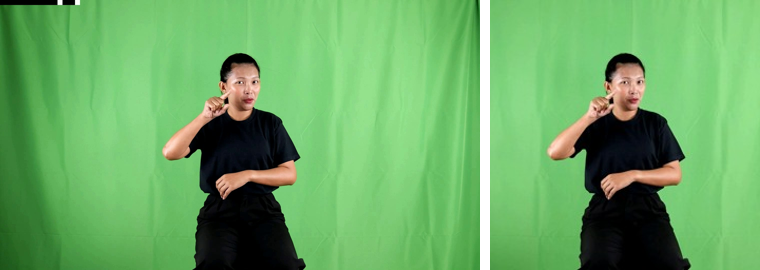

   left = full frame      right = what the model will see


### A_60fps_1_general_hospital

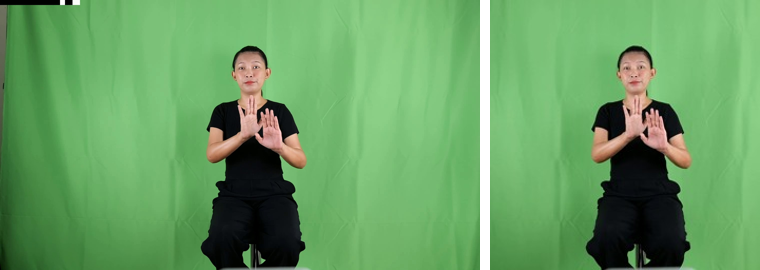

   left = full frame      right = what the model will see


### B_120fps_10_nutrition_and_diet

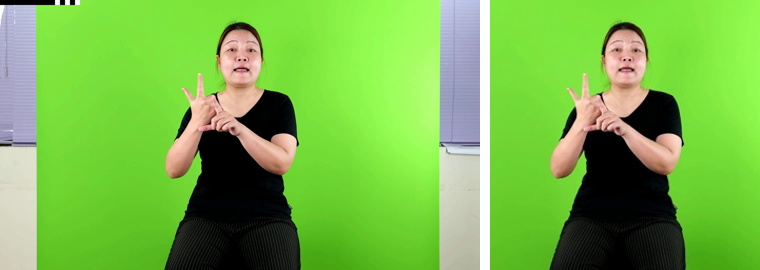

   left = full frame      right = what the model will see


### B_60fps_1_general_hospital_interaction

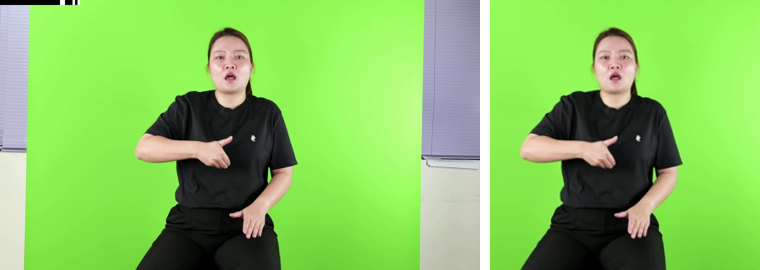

   left = full frame      right = what the model will see


In [6]:
# Cell 3 — display the samples
from IPython.display import display, Markdown

for full in sorted(SAMPLE_DIR.glob("*_FULL.jpg")):
    crop = full.with_name(full.name.replace("_FULL", "_CROPPED"))
    display(Markdown(f"### {full.name.replace('_FULL.jpg','')}"))
    a = Image.open(full).resize((480, 270))
    b = Image.open(crop).resize((270, 270))
    canvas = Image.new("RGB", (a.width + b.width + 10, 270), "white")
    canvas.paste(a, (0, 0))
    canvas.paste(b, (a.width + 10, 0))
    display(canvas)
    print("   left = full frame      right = what the model will see")

In [9]:
# Cell 3b — find the signer in each clip using the green background
SAMPLE_CLIPS  = 50     # how many clips to check
FRAMES_PER    = 5       # frames per clip
SCAN_W        = 480     # work at low resolution for speed

def signer_box(img):
    """Return (x0, y0, x1, y1) of the non-green area, in 0-1 fractions."""
    im = img.resize((SCAN_W, int(SCAN_W * img.height / img.width)))
    a  = np.asarray(im).astype(np.int16)
    r, g, b = a[:, :, 0], a[:, :, 1], a[:, :, 2]
    not_green = ~((g > r + 25) & (g > b + 25))          # True = person
    ys, xs = np.where(not_green)
    if len(xs) < 50:
        return None
    return (xs.min()/im.width,  ys.min()/im.height,
            xs.max()/im.width,  ys.max()/im.height)

samp = (rgb.groupby("station", group_keys=False)
           .apply(lambda g: g.sample(min(SAMPLE_CLIPS//2, len(g)), random_state=42)))

boxes = []
for _, r in tqdm(list(samp.iterrows())):
    try:
        with av.open(r.path) as c:
            st = next(s for s in c.streams if s.type == "video")
            total = st.frames or 300
            want  = set(np.linspace(0, total - 1, FRAMES_PER).astype(int))
            for i, frame in enumerate(c.decode(video=0)):
                if i in want:
                    bb = signer_box(frame.to_image())
                    if bb:
                        boxes.append({"station": r.station, "cid": r.cid,
                                      "x0": bb[0], "y0": bb[1], "x1": bb[2], "y1": bb[3]})
                if i > max(want):
                    break
    except Exception as e:
        print(f"skip {r.cid}: {e}")

bx = pd.DataFrame(boxes)
print(f"\n{len(bx)} frames measured from {bx.cid.nunique()} clips\n")

print("="*72)
print("WHERE THE SIGNER IS  (0 = left/top edge, 1 = right/bottom edge)")
print("="*72)
for st, g in bx.groupby("station"):
    print(f"\n{st}   ({g.cid.nunique()} clips)")
    print(g[["x0","x1","y0","y1"]].describe(
            percentiles=[.01,.5,.99]).loc[["min","1%","50%","99%","max"]].round(3).to_string())

print("\n" + "="*72)
print("DOES THE CURRENT CENTRE CROP CUT THE SIGNER?")
print("="*72)
# centre square of a 16:9 frame keeps x from 0.281 to 0.719
L, R = (1 - 9/16) / 2, 1 - (1 - 9/16) / 2
print(f"centre square keeps x from {L:.3f} to {R:.3f}")
cut = bx[(bx.x0 < L) | (bx.x1 > R)]
print(f"\nframes where the signer goes outside that box: {len(cut)} of {len(bx)}  "
      f"({100*len(cut)/len(bx):.1f}%)")
if len(cut):
    print(f"clips affected: {cut.cid.nunique()}")
    print("\nworst cases:")
    print(cut.assign(over=np.maximum(L - cut.x0, cut.x1 - R))
             .nlargest(10, "over")[["station","cid","x0","x1","over"]].round(3).to_string(index=False))

/tmp/ipykernel_2719672/2468008244.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(SAMPLE_CLIPS//2, len(g)), random_state=42)))


  0%|          | 0/50 [00:00<?, ?it/s]


250 frames measured from 50 clips

WHERE THE SIGNER IS  (0 = left/top edge, 1 = right/bottom edge)

stationA_2ndbatch   (25 clips)
      x0     x1   y0     y1
min  0.0  0.598  0.0  0.996
1%   0.0  0.620  0.0  0.996
50%  0.0  0.642  0.0  0.996
99%  0.0  0.679  0.0  0.996
max  0.0  0.690  0.0  0.996

stationB_2ndbatch   (25 clips)
      x0     x1   y0     y1
min  0.0  0.998  0.0  0.996
1%   0.0  0.998  0.0  0.996
50%  0.0  0.998  0.0  0.996
99%  0.0  0.998  0.0  0.996
max  0.0  0.998  0.0  0.996

DOES THE CURRENT CENTRE CROP CUT THE SIGNER?
centre square keeps x from 0.219 to 0.781

frames where the signer goes outside that box: 250 of 250  (100.0%)
clips affected: 50

worst cases:
          station          cid  x0    x1  over
stationA_2ndbatch b2_A_03_0065 0.0 0.633 0.219
stationA_2ndbatch b2_A_03_0065 0.0 0.644 0.219
stationA_2ndbatch b2_A_03_0065 0.0 0.629 0.219
stationA_2ndbatch b2_A_03_0065 0.0 0.598 0.219
stationA_2ndbatch b2_A_03_0065 0.0 0.635 0.219
stationA_2ndbatch b2_A_05_00

In [11]:
# Cell 3c — find the signer using the largest connected non-green blob
import cv2

SAMPLE_CLIPS = 50
FRAMES_PER   = 4
SCAN_W       = 480

def signer_box(pil_img):
    """Largest non-green blob = the signer. Returns (x0,y0,x1,y1) as 0-1 fractions."""
    im = pil_img.resize((SCAN_W, int(SCAN_W * pil_img.height / pil_img.width)))
    a  = np.asarray(im)

    # green screen detection in HSV is more reliable than raw RGB
    hsv = cv2.cvtColor(a, cv2.COLOR_RGB2HSV)
    green = cv2.inRange(hsv, (35, 60, 40), (90, 255, 255))     # hue 35-90 = green
    person = cv2.bitwise_not(green)

    # clean up: remove specks, fill small holes
    k = np.ones((5, 5), np.uint8)
    person = cv2.morphologyEx(person, cv2.MORPH_OPEN,  k, iterations=2)
    person = cv2.morphologyEx(person, cv2.MORPH_CLOSE, k, iterations=2)

    n, lbl, stats, _ = cv2.connectedComponentsWithStats(person, 8)
    if n <= 1:
        return None
    big = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])           # skip background label 0
    x, y, w, h, area = stats[big]
    if area < 0.01 * person.size:
        return None
    H, W = person.shape
    return (x/W, y/H, (x+w)/W, (y+h)/H)

samp = (rgb.groupby("station", group_keys=False)
           .apply(lambda g: g.sample(min(SAMPLE_CLIPS//2, len(g)), random_state=0)))

boxes = []
for _, r in tqdm(list(samp.iterrows())):
    try:
        with av.open(r.path) as c:
            st    = next(s for s in c.streams if s.type == "video")
            total = st.frames or 300
            want  = set(np.linspace(0, total - 1, FRAMES_PER).astype(int))
            for i, frame in enumerate(c.decode(video=0)):
                if i in want:
                    bb = signer_box(frame.to_image())
                    if bb:
                        boxes.append({"station": r.station, "cid": r.cid,
                                      "x0": bb[0], "y0": bb[1], "x1": bb[2], "y1": bb[3]})
                if i > max(want):
                    break
    except Exception as e:
        print(f"skip {r.cid}: {e}")

bx = pd.DataFrame(boxes)
print(f"\n{len(bx)} frames from {bx.cid.nunique()} clips\n")

print("="*72); print("WHERE THE SIGNER IS (0 = left edge, 1 = right edge)"); print("="*72)
for st, g in bx.groupby("station"):
    print(f"\n{st}  ({g.cid.nunique()} clips)")
    print(g[["x0","x1","y0","y1"]].describe(
            percentiles=[.01,.5,.99]).loc[["min","1%","50%","99%","max"]].round(3).to_string())

L, R = (1 - 9/16)/2, 1 - (1 - 9/16)/2
print("\n" + "="*72)
print(f"CENTRE CROP KEEPS x FROM {L:.3f} TO {R:.3f}")
print("="*72)
cut = bx[(bx.x0 < L) | (bx.x1 > R)]
print(f"frames where the signer leaves that box: {len(cut)} of {len(bx)} ({100*len(cut)/len(bx):.1f}%)")
if len(cut):
    print(f"clips affected: {cut.cid.nunique()} of {bx.cid.nunique()}")
    print(cut.assign(over=np.maximum(L - cut.x0, cut.x1 - R))
             .nlargest(8, "over")[["station","cid","x0","x1","over"]].round(3).to_string(index=False))

/tmp/ipykernel_2719672/3399820925.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(SAMPLE_CLIPS//2, len(g)), random_state=0)))


  0%|          | 0/50 [00:00<?, ?it/s]


200 frames from 50 clips

WHERE THE SIGNER IS (0 = left edge, 1 = right edge)

stationA_2ndbatch  (25 clips)
        x0     x1     y0   y1
min  0.340  0.606  0.189  1.0
1%   0.346  0.610  0.189  1.0
50%  0.381  0.638  0.252  1.0
99%  0.406  0.665  0.274  1.0
max  0.410  0.675  0.278  1.0

stationB_2ndbatch  (25 clips)
        x0     x1     y0   y1
min  0.292  0.594  0.070  1.0
1%   0.314  0.594  0.074  1.0
50%  0.360  0.646  0.144  1.0
99%  0.402  0.698  0.248  1.0
max  0.402  0.710  0.248  1.0

CENTRE CROP KEEPS x FROM 0.219 TO 0.781
frames where the signer leaves that box: 0 of 200 (0.0%)


/tmp/ipykernel_2719672/3157364068.py:20: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  show = rgb.groupby(["station","fps"], group_keys=False).apply(lambda g: g.sample(2, random_state=1))


b2_A_01_0032  A  60.0 fps  1_general_hospital


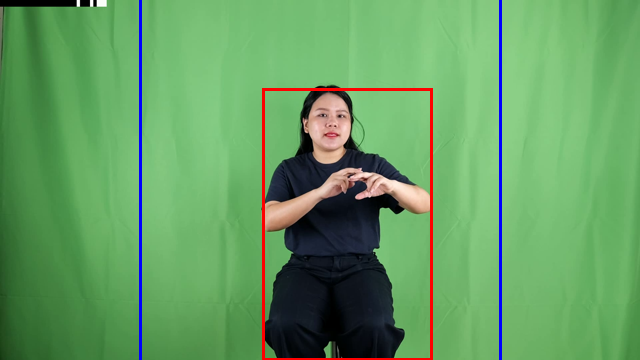

   red = detected signer     blue = crop edges
b2_A_06_0055  A  60.0 fps  6_common_symptoms


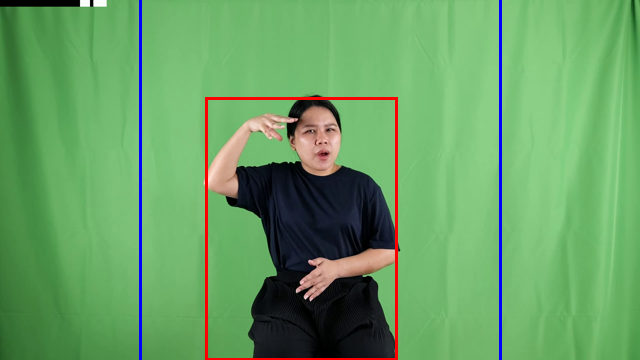

   red = detected signer     blue = crop edges
b2_A_12_0043  A  120.0 fps  12_mental_health


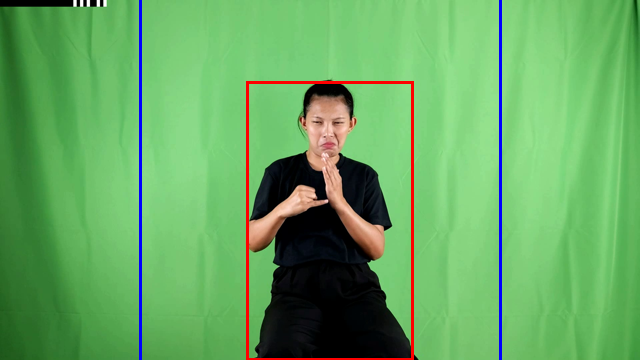

   red = detected signer     blue = crop edges
b2_A_12_0099  A  120.0 fps  12_mental_health


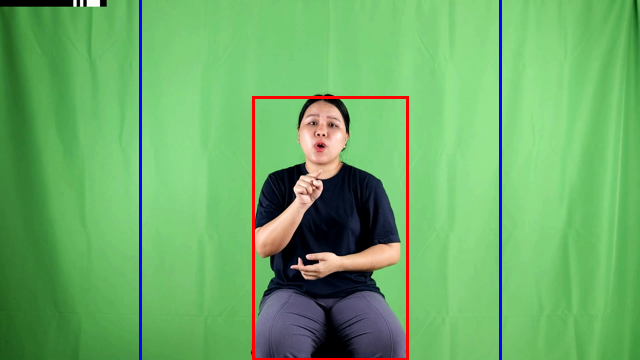

   red = detected signer     blue = crop edges
b2_B_01_0127  B  60.0 fps  1_general_hospital_interaction


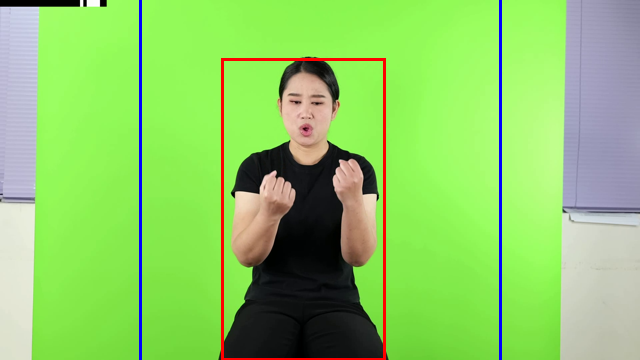

   red = detected signer     blue = crop edges
b2_B_06_0148  B  60.0 fps  6_common_symptons


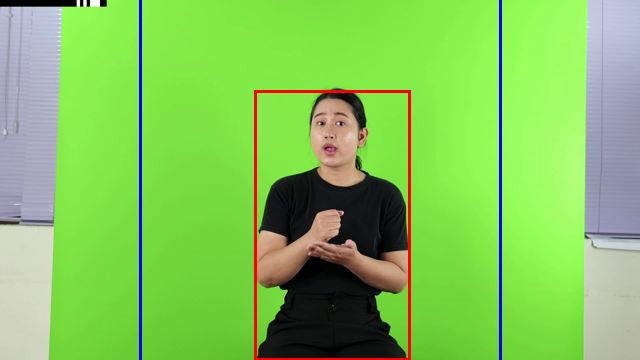

   red = detected signer     blue = crop edges
b2_B_12_0144  B  120.0 fps  12_mental_health_interaction


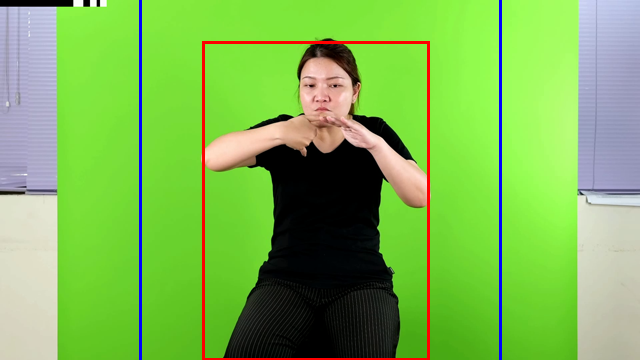

   red = detected signer     blue = crop edges
b2_B_12_0200  B  120.0 fps  12_mental_health_interaction


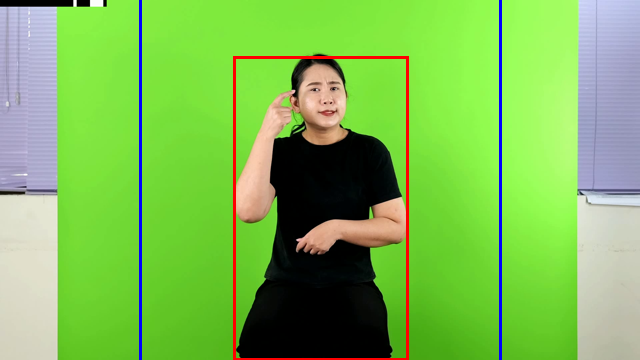

   red = detected signer     blue = crop edges


In [12]:
# Cell 3d — draw the detected box and the crop line on real frames
from PIL import ImageDraw

def annotate(path):
    with av.open(path) as c:
        st = next(s for s in c.streams if s.type == "video")
        mid = (st.frames or 300) // 2
        for i, f in enumerate(c.decode(video=0)):
            if i == mid:
                img = f.to_image(); break
    bb = signer_box(img)
    img = img.resize((640, 360))
    d = ImageDraw.Draw(img)
    if bb:
        d.rectangle([bb[0]*640, bb[1]*360, bb[2]*640, bb[3]*360], outline=(255,0,0), width=3)
    d.line([L*640, 0, L*640, 360], fill=(0,0,255), width=3)      # crop edges
    d.line([R*640, 0, R*640, 360], fill=(0,0,255), width=3)
    return img

show = rgb.groupby(["station","fps"], group_keys=False).apply(lambda g: g.sample(2, random_state=1))
for _, r in show.iterrows():
    print(f"{r.cid}  {r.station[7:8]}  {r.fps} fps  {r.category}")
    display(annotate(r.path))
    print("   red = detected signer     blue = crop edges")

In [13]:
# Cell 3e — clear the test clips
import shutil
for _, r in rgb.head(5).iterrows():
    d = OUT_ROOT / r.cid
    if d.exists():
        shutil.rmtree(d)
        print("removed", d.name)

removed b2_A_10_0001
removed b2_A_10_0002
removed b2_A_10_0003
removed b2_A_10_0004
removed b2_A_10_0005


In [7]:
# Cell 4 — extract a few clips as a test
def extract_one(row, out_dir, size=SIZE, quality=QUALITY):
    """Decode one video, keep every Nth frame, save as JPEG."""
    stride = max(1, int(row.stride))
    tmp = out_dir.with_name(out_dir.name + ".partial")
    if tmp.exists():
        shutil.rmtree(tmp)
    tmp.mkdir(parents=True, exist_ok=True)

    kept = 0
    with av.open(str(row.path)) as c:
        c.streams.video[0].thread_type = "AUTO"
        for i, frame in enumerate(c.decode(video=0)):
            if i % stride:
                continue
            center_square(frame.to_image()).resize(
                (size, size), Image.BICUBIC
            ).save(tmp / f"{kept:06d}.jpg", quality=quality)
            kept += 1

    if out_dir.exists():
        shutil.rmtree(out_dir)
    tmp.rename(out_dir)          # rename only when finished
    return kept

OUT_ROOT.mkdir(parents=True, exist_ok=True)

for _, r in rgb.head(5).iterrows():
    n = extract_one(r, OUT_ROOT / r.cid)
    print(f"{r.cid}  {r.fps} fps  stride={r.stride}  "
          f"{r.nb_frames} frames -> {n} saved  (expected ~{r.frames_after})")

b2_A_10_0001  120.0 fps  stride=4  775 frames -> 194 saved  (expected ~194)
b2_A_10_0002  120.0 fps  stride=4  973 frames -> 244 saved  (expected ~243)
b2_A_10_0003  120.0 fps  stride=4  899 frames -> 225 saved  (expected ~225)
b2_A_10_0004  120.0 fps  stride=4  1147 frames -> 287 saved  (expected ~287)
b2_A_10_0005  120.0 fps  stride=4  1176 frames -> 294 saved  (expected ~294)


b2_A_10_0001: 194 frames


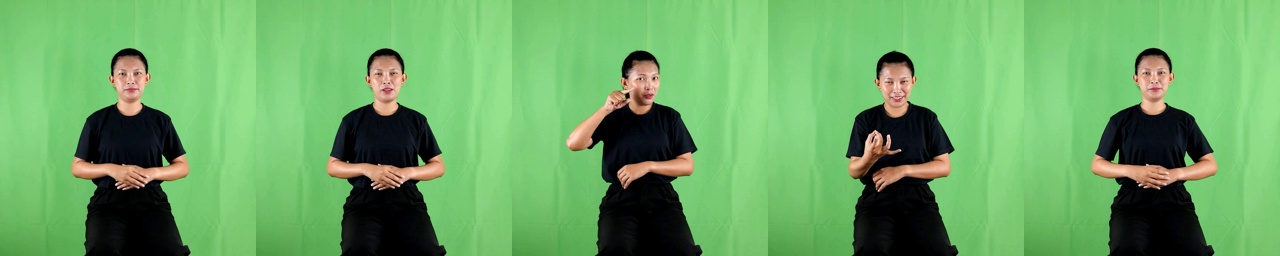

In [8]:
# Cell 5 — look at the extracted frames of one clip
cid = rgb.iloc[0].cid
files = sorted((OUT_ROOT / cid).glob("*.jpg"))
print(f"{cid}: {len(files)} frames")

row = Image.new("RGB", (SIZE * 5, SIZE), "white")
for k, idx in enumerate(np.linspace(0, len(files) - 1, 5).astype(int)):
    row.paste(Image.open(files[idx]), (k * SIZE, 0))
display(row)

In [15]:
# Cell 6 — write the standalone script
script = f'''"""
extract_frames.py — batch 2 RGB videos -> {TARGET_FPS} fps JPEG frames.
Safe to re-run: finished clips are skipped.
"""
import argparse, re, shutil
from pathlib import Path
import av, pandas as pd
from PIL import Image
from tqdm import tqdm

HOME, ARCH = Path.home(), Path.home() / "dataset_arch" / "SignLanguage"
REPORTS    = Path.home() / "work" / "signlanguage" / "reports"
OUT_ROOT   = ARCH / "frames_batch2_{TARGET_FPS}fps"
TARGET_FPS, SIZE, QUALITY = {TARGET_FPS}, {SIZE}, {QUALITY}

def center_square(img):
    w, h = img.size; s = min(w, h)
    return img.crop(((w-s)//2, (h-s)//2, (w+s)//2, (h+s)//2))

def clip_id(r):
    st = "A" if "stationA" in r.station else "B"
    return f"b2_{{st}}_{{int(re.match(r'^(\\\\d+)', r.category).group(1)):02d}}_{{int(r.id):04d}}"

def extract_one(r, out_dir):
    stride = max(1, round(r.fps / TARGET_FPS))
    tmp = out_dir.with_name(out_dir.name + ".partial")
    if tmp.exists(): shutil.rmtree(tmp)
    tmp.mkdir(parents=True, exist_ok=True)
    kept = 0
    with av.open(str(r.path)) as c:
        c.streams.video[0].thread_type = "AUTO"
        for i, frame in enumerate(c.decode(video=0)):
            if i % stride: continue
            center_square(frame.to_image()).resize((SIZE, SIZE), Image.BICUBIC) \\
                .save(tmp / f"{{kept:06d}}.jpg", quality=QUALITY)
            kept += 1
    if out_dir.exists(): shutil.rmtree(out_dir)
    tmp.rename(out_dir)
    return kept

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dry-run", action="store_true")
    ap.add_argument("--limit", type=int, default=None)
    a = ap.parse_args()

    rgb = pd.read_csv(REPORTS / "batch2_rgb.csv")
    rgb["cid"] = rgb.apply(clip_id, axis=1)
    assert rgb.cid.is_unique, "clip ids not unique"
    OUT_ROOT.mkdir(parents=True, exist_ok=True)

    todo, done = [], 0
    for _, r in rgb.iterrows():
        d = OUT_ROOT / r.cid
        if d.is_dir() and any(d.iterdir()): done += 1
        else: todo.append(r)
    if a.limit: todo = todo[:a.limit]

    print(f"total {{len(rgb)}} | done {{done}} | to do {{len(todo)}}")
    print(f"out: {{OUT_ROOT}}  ({{TARGET_FPS}} fps, {{SIZE}}x{{SIZE}}, q{{QUALITY}})")
    if a.dry_run:
        for r in todo[:5]:
            print(f"  {{r.cid}} {{r.fps}}fps stride={{round(r.fps/TARGET_FPS)}} "
                  f"{{r.nb_frames}} -> ~{{round(r.nb_frames/round(r.fps/TARGET_FPS))}}")
        return

    log = []
    for r in tqdm(todo):
        try:
            log.append({{"cid": r.cid, "frames": extract_one(r, OUT_ROOT / r.cid),
                         "fps": r.fps, "ok": True, "error": ""}})
        except Exception as e:
            log.append({{"cid": r.cid, "frames": 0, "fps": r.fps, "ok": False,
                         "error": f"{{type(e).__name__}}: {{e}}"}})
            print(f"[FAIL] {{r.cid}}: {{e}}")

    d = pd.DataFrame(log)
    d.to_csv(REPORTS / "extract_frames_log.csv", index=False)
    print(f"OK {{int(d.ok.sum())}} | FAILED {{int((~d.ok).sum())}} | "
          f"frames {{int(d.frames.sum()):,}}")

if __name__ == "__main__":
    main()
'''

p = WORK / "extract_frames.py"
p.write_text(script)
print(f"written -> {p}")

written -> /home/soehn/work/signlanguage/extract_frames.py


In [16]:
# Cell 7 — verify the extracted frames
log = pd.read_csv(REPORTS / "extract_frames_log.csv")
folders = sorted(p for p in OUT_ROOT.iterdir() if p.is_dir())

print(f"folders on disk : {len(folders)}   (expected 2320)")
print(f"partial folders : {sum('partial' in p.name for p in folders)}")

# count frames per folder and compare with what was predicted
counts = {p.name: len(list(p.glob('*.jpg'))) for p in folders}
chk = rgb.copy()
chk["actual"]   = chk.cid.map(counts)
chk["expected"] = (chk.nb_frames / chk.stride).round().astype(int)
chk["diff"]     = (chk.actual - chk.expected).abs()

print(f"\nmissing folders : {int(chk.actual.isna().sum())}")
print(f"empty folders   : {int((chk.actual == 0).sum())}")
print(f"off by >1 frame : {int((chk['diff'] > 1).sum())}")
print(f"total frames    : {int(chk.actual.sum()):,}")

print("\nframes per clip:")
print(chk.groupby("fps")["actual"].describe()[["count","mean","50%","min","max"]].round(0).to_string())

# check image size and that files actually open
from PIL import Image
bad = []
for p in np.random.default_rng(0).choice(folders, 20, replace=False):
    f = sorted(p.glob("*.jpg"))
    try:
        im = Image.open(f[0]); im.load()
        if im.size != (SIZE, SIZE):
            bad.append((p.name, im.size))
    except Exception as e:
        bad.append((p.name, str(e)))
print(f"\n20 random clips checked, problems: {len(bad)}")
for b in bad: print("   ", b)

folders on disk : 2320   (expected 2320)
partial folders : 0

missing folders : 0
empty folders   : 0
off by >1 frame : 0
total frames    : 621,940

frames per clip:
        count   mean    50%    min    max
fps                                      
60.0    967.0  244.0  237.0  112.0  552.0
120.0  1353.0  285.0  273.0  142.0  681.0

20 random clips checked, problems: 0


In [25]:
# Cell 0 — setup
from pathlib import Path
import os, sys, time, importlib.util
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

HOME      = Path.home()
ARCH      = HOME / "dataset_arch" / "SignLanguage"
WORK      = HOME / "work" / "signlanguage"
REPORTS   = WORK / "reports"
SPAMO_DIR = HOME / "work" / "SpaMo_ref"

FRAMES   = ARCH / "frames_batch2_30fps"
FEAT_DIR = ARCH / "features_b2_30fps"
SPATIAL  = FEAT_DIR / "spatial"
MOTION   = FEAT_DIR / "motion"
SPATIAL.mkdir(parents=True, exist_ok=True)
MOTION.mkdir(parents=True, exist_ok=True)

# settings — exactly SpaMo's
VIT_MODEL   = "openai/clip-vit-large-patch14"
MAE_MODEL   = "MCG-NJU/videomae-large"
S2_SCALES   = [1, 2]
MAE_WINDOW  = 16
MAE_OVERLAP = 8
BATCH_SIZE  = 16          # lower this if you run out of GPU memory
DEVICE      = "cuda:1"    # change if another GPU is free

clips = sorted(p.name for p in FRAMES.iterdir() if p.is_dir())
print(f"clips with frames : {len(clips)}")
print(f"device            : {DEVICE}")
print(f"torch cuda        : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"   cuda:{i}  {p.name}  {p.total_memory/1e9:.0f} GB")

clips with frames : 2320
device            : cuda:1
torch cuda        : True
   cuda:0  NVIDIA RTX A6000  51 GB
   cuda:1  NVIDIA RTX A6000  51 GB


In [26]:
# Cell 1 — load SpaMo's helpers (unchanged, straight from their repo)
def load_from_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod  = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

s2w     = load_from_file("s2wrapper", SPAMO_DIR / "utils" / "s2wrapper.py")
helpers = load_from_file("helpers",   SPAMO_DIR / "utils" / "helpers.py")

multiscale_forward      = s2w.forward
sliding_window_for_list = helpers.sliding_window_for_list

# quick sanity check of the window maths
demo = list(range(40))
w = sliding_window_for_list(demo, window_size=16, overlap_size=8)
print(f"40 frames -> {len(w)} windows, first={w[0][0]}-{w[0][-1]}, last={w[-1][0]}-{w[-1][-1]}")
print("expected: 4 windows (step 8, incomplete tail dropped)")

40 frames -> 4 windows, first=0-15, last=24-39
expected: 4 windows (step 8, incomplete tail dropped)


In [27]:
# Cell 2 — load the two encoders
from transformers import (AutoImageProcessor, CLIPVisionModel,
                          VideoMAEModel, VideoMAEImageProcessor)

device = torch.device(DEVICE)

print("loading CLIP ViT-L/14 ...")
vit_model = CLIPVisionModel.from_pretrained(
    VIT_MODEL, output_hidden_states=True).to(device).eval()
vit_proc  = AutoImageProcessor.from_pretrained(VIT_MODEL)
print("   ok")

print("loading VideoMAE-L ...")
mae_model = VideoMAEModel.from_pretrained(MAE_MODEL).to(device).eval()
mae_proc  = VideoMAEImageProcessor.from_pretrained(MAE_MODEL)
print("   ok")

print(f"\nGPU memory used: {torch.cuda.memory_allocated(device)/1e9:.2f} GB")

loading CLIP ViT-L/14 ...
   ok
loading VideoMAE-L ...
   ok

GPU memory used: 2.43 GB


In [28]:
# Cell 3 — the two extraction functions (mirroring SpaMo exactly)

@torch.no_grad()
def vit_forward_features(inputs):
    return vit_model(inputs).hidden_states[-1]          # nth_layer = -1

@torch.no_grad()
def extract_spatial(images, batch_size=BATCH_SIZE):
    """images: list of PIL. Returns (T, 2048) float32."""
    out = []
    for j in range(0, len(images), batch_size):
        batch  = images[j:j + batch_size]
        inputs = vit_proc(list(batch), return_tensors="pt").to(device).pixel_values
        feats  = multiscale_forward(vit_forward_features, inputs,
                                    scales=S2_SCALES, num_prefix_token=1)
        out.append(feats[:, 0].float().cpu().numpy())   # CLS token
    return np.concatenate(out, axis=0)

@torch.no_grad()
def extract_motion(images, batch_size=BATCH_SIZE):
    """images: list of PIL. Returns (N, 1024) float32."""
    imgs = list(images)
    if len(imgs) < MAE_WINDOW:                          # pad by repeating the last frame
        imgs = imgs + [imgs[-1]] * (MAE_WINDOW - len(imgs))
    windows = sliding_window_for_list(imgs, window_size=MAE_WINDOW,
                                      overlap_size=MAE_OVERLAP)
    out = []
    for j in range(0, len(windows), batch_size):
        batch  = windows[j:j + batch_size]
        inputs = mae_proc(images=batch, return_tensors="pt").to(device)
        feats  = mae_model(**inputs, output_hidden_states=True).hidden_states[-1][:, 0]
        out.append(feats.float().cpu().numpy())
    return np.concatenate(out, axis=0)

def load_frames(cid):
    files = sorted((FRAMES / cid).glob("*.jpg"))
    return [Image.open(f).convert("RGB") for f in files]

In [29]:
# Cell 4 — test on 3 clips, check shapes and timing
for cid in clips[:3]:
    imgs = load_frames(cid)
    T = len(imgs)

    t0 = time.time(); sp = extract_spatial(imgs); t_sp = time.time() - t0
    t0 = time.time(); mo = extract_motion(imgs);  t_mo = time.time() - t0

    n_expect = (T - MAE_WINDOW) // (MAE_WINDOW - MAE_OVERLAP) + 1
    print(f"{cid}  T={T}")
    print(f"   spatial {sp.shape}  {sp.dtype}  {t_sp:5.1f}s   (expect ({T}, 2048))")
    print(f"   motion  {mo.shape}  {mo.dtype}  {t_mo:5.1f}s   (expect ({n_expect}, 1024))")
    print(f"   size on disk: {(sp.nbytes + mo.nbytes)/1e6:.1f} MB")
    print(f"   GPU peak: {torch.cuda.max_memory_allocated(device)/1e9:.1f} GB")

b2_A_01_0001  T=199
   spatial (199, 2048)  float32   11.1s   (expect (199, 2048))
   motion  (23, 1024)  float32    2.6s   (expect (23, 1024))
   size on disk: 1.7 MB
   GPU peak: 6.3 GB
b2_A_01_0002  T=213
   spatial (213, 2048)  float32   11.7s   (expect (213, 2048))
   motion  (25, 1024)  float32    2.6s   (expect (25, 1024))
   size on disk: 1.8 MB
   GPU peak: 6.3 GB
b2_A_01_0003  T=197
   spatial (197, 2048)  float32   10.9s   (expect (197, 2048))
   motion  (23, 1024)  float32    2.4s   (expect (23, 1024))
   size on disk: 1.7 MB
   GPU peak: 6.3 GB


In [30]:
# Cell 5 — where is the time going, and what batch size is best?
import gc

cid  = clips[0]

# how much is just reading JPEGs from disk?
t0 = time.time(); imgs = load_frames(cid); t_io = time.time() - t0
print(f"clip {cid}, T={len(imgs)}")
print(f"  loading {len(imgs)} jpegs from disk : {t_io:5.2f}s")

# warm up
_ = extract_spatial(imgs, batch_size=16)
torch.cuda.synchronize(device)

print("\nSPATIAL (the bottleneck):")
for bs in [16, 32, 64, 96]:
    try:
        torch.cuda.reset_peak_memory_stats(device)
        t0 = time.time()
        sp = extract_spatial(imgs, batch_size=bs)
        torch.cuda.synchronize(device)
        dt = time.time() - t0
        peak = torch.cuda.max_memory_allocated(device) / 1e9
        print(f"  batch {bs:3d}: {dt:6.2f}s   peak {peak:5.1f} GB   "
              f"est. total {dt * 2320 / 3600:5.2f} h")
    except torch.cuda.OutOfMemoryError:
        print(f"  batch {bs:3d}: OUT OF MEMORY")
        torch.cuda.empty_cache(); gc.collect()

print("\nMOTION:")
for bs in [16, 32, 64]:
    try:
        torch.cuda.reset_peak_memory_stats(device)
        t0 = time.time()
        mo = extract_motion(imgs, batch_size=bs)
        torch.cuda.synchronize(device)
        dt = time.time() - t0
        peak = torch.cuda.max_memory_allocated(device) / 1e9
        print(f"  batch {bs:3d}: {dt:6.2f}s   peak {peak:5.1f} GB")
    except torch.cuda.OutOfMemoryError:
        print(f"  batch {bs:3d}: OUT OF MEMORY")
        torch.cuda.empty_cache(); gc.collect()

clip b2_A_01_0001, T=199
  loading 199 jpegs from disk :  0.20s

SPATIAL (the bottleneck):
  batch  16:  11.02s   peak   5.1 GB   est. total  7.10 h
  batch  32:  10.92s   peak   7.8 GB   est. total  7.04 h
  batch  64:  10.93s   peak  13.1 GB   est. total  7.04 h
  batch  96:  10.88s   peak  18.4 GB   est. total  7.01 h

MOTION:
  batch  16:   2.44s   peak   6.3 GB
  batch  32:   2.45s   peak   8.0 GB
  batch  64:   2.44s   peak   8.0 GB


In [31]:
# Cell 5b — optional: does bf16 change the features, and how much faster?
@torch.no_grad()
def extract_spatial_bf16(images, batch_size=32):
    out = []
    for j in range(0, len(images), batch_size):
        batch  = images[j:j + batch_size]
        inputs = vit_proc(list(batch), return_tensors="pt").to(device).pixel_values
        with torch.autocast("cuda", dtype=torch.bfloat16):
            feats = multiscale_forward(vit_forward_features, inputs,
                                       scales=S2_SCALES, num_prefix_token=1)
        out.append(feats[:, 0].float().cpu().numpy())
    return np.concatenate(out, axis=0)

t0 = time.time(); sp32 = extract_spatial(imgs, 32);      t32 = time.time() - t0
t0 = time.time(); sp16 = extract_spatial_bf16(imgs, 32); t16 = time.time() - t0

d = np.abs(sp32 - sp16)
print(f"fp32  {t32:5.2f}s")
print(f"bf16  {t16:5.2f}s   ({t32/t16:.2f}x faster)")
print(f"max difference      : {d.max():.5f}")
print(f"mean difference     : {d.mean():.6f}")
print(f"relative to feature : {d.mean() / np.abs(sp32).mean() * 100:.3f}%")
print(f"cosine similarity   : "
      f"{np.mean([np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b)) for a,b in zip(sp32, sp16)]):.6f}")

fp32  10.82s
bf16   3.09s   (3.50x faster)
max difference      : 0.15285
mean difference     : 0.007298
relative to feature : 2.026%
cosine similarity   : 0.999792


In [32]:
# Cell 6 — check the saved .npy files load correctly
sp_files = sorted(SPATIAL.glob("*_s2wrapping.npy"))
mo_files = sorted(MOTION.glob("*_overlap-8.npy"))
print(f"spatial files: {len(sp_files)}")
print(f"motion  files: {len(mo_files)}")
print(f"leftover .tmp: {len(list(FEAT_DIR.rglob('*.tmp.npy')))}   (must be 0)")

for f in sp_files[:5]:
    cid = f.name.replace("_s2wrapping.npy", "")
    sp  = np.load(f)
    mo  = np.load(MOTION / f"{cid}_overlap-8.npy")
    T   = len(list((FRAMES / cid).glob("*.jpg")))
    n_expect = (T - 16) // 8 + 1
    ok_sp = sp.shape == (T, 2048)
    ok_mo = mo.shape == (n_expect, 1024)
    print(f"{cid}  frames={T}")
    print(f"   spatial {str(sp.shape):14s} {sp.dtype}  {'OK' if ok_sp else 'WRONG'}")
    print(f"   motion  {str(mo.shape):14s} {mo.dtype}  {'OK' if ok_mo else 'WRONG'}")
    print(f"   finite: {np.isfinite(sp).all()} / {np.isfinite(mo).all()}   "
          f"range sp [{sp.min():.2f}, {sp.max():.2f}]")

spatial files: 5
motion  files: 5
leftover .tmp: 0   (must be 0)
b2_A_01_0001  frames=199
   spatial (199, 2048)    float32  OK
   motion  (23, 1024)     float32  OK
   finite: True / True   range sp [-4.09, 6.61]
b2_A_01_0002  frames=213
   spatial (213, 2048)    float32  OK
   motion  (25, 1024)     float32  OK
   finite: True / True   range sp [-4.04, 6.42]
b2_A_01_0003  frames=197
   spatial (197, 2048)    float32  OK
   motion  (23, 1024)     float32  OK
   finite: True / True   range sp [-4.00, 6.40]
b2_A_01_0004  frames=196
   spatial (196, 2048)    float32  OK
   motion  (23, 1024)     float32  OK
   finite: True / True   range sp [-3.93, 6.54]
b2_A_01_0005  frames=187
   spatial (187, 2048)    float32  OK
   motion  (22, 1024)     float32  OK
   finite: True / True   range sp [-4.16, 6.34]


In [33]:
# Cell 7 — full verification of the extracted features
import numpy as np, pandas as pd
from pathlib import Path

FRAMES  = ARCH / "frames_batch2_30fps"
SPATIAL = ARCH / "features_b2_30fps" / "spatial"
MOTION  = ARCH / "features_b2_30fps" / "motion"

clips = sorted(p.name for p in FRAMES.iterdir() if p.is_dir())
print(f"clips        : {len(clips)}")
print(f"spatial files: {len(list(SPATIAL.glob('*.npy')))}")
print(f"motion files : {len(list(MOTION.glob('*.npy')))}")
print(f"leftover tmp : {len(list((ARCH/'features_b2_30fps').rglob('*.tmp.npy')))}   (must be 0)")

rows = []
for cid in tqdm(clips):
    T  = len(list((FRAMES / cid).glob("*.jpg")))
    sp = SPATIAL / f"{cid}_s2wrapping.npy"
    mo = MOTION  / f"{cid}_overlap-8.npy"
    r = {"cid": cid, "T": T, "sp_exists": sp.exists(), "mo_exists": mo.exists(),
         "sp_ok": False, "mo_ok": False, "finite": False}
    if sp.exists() and mo.exists():
        a = np.load(sp, mmap_mode="r")
        b = np.load(mo, mmap_mode="r")
        r["sp_shape"] = str(a.shape)
        r["mo_shape"] = str(b.shape)
        r["sp_ok"] = a.shape == (T, 2048)
        r["mo_ok"] = b.shape == ((T - 16)//8 + 1, 1024)
        r["finite"] = bool(np.isfinite(a[::50]).all() and np.isfinite(b).all())
    rows.append(r)

v = pd.DataFrame(rows)
print("\n" + "="*50)
print(f"missing spatial : {int((~v['sp_exists']).sum())}")
print(f"missing motion  : {int((~v['mo_exists']).sum())}")
print(f"wrong sp shape  : {int((~v['sp_ok']).sum())}")
print(f"wrong mo shape  : {int((~v['mo_ok']).sum())}")
print(f"non-finite      : {int((~v['finite']).sum())}")
print("="*50)

bad = v[~(v["sp_ok"] & v["mo_ok"] & v["finite"])]
if len(bad):
    print("\nPROBLEM CLIPS:")
    print(bad.head(20).to_string(index=False))
else:
    print("\nAll clips OK.")
    print(f"stationA: {sum(c.startswith('b2_A_') for c in clips)}")
    print(f"stationB: {sum(c.startswith('b2_B_') for c in clips)}")

v.to_csv(REPORTS / "batch2_features_check.csv", index=False)

clips        : 2320
spatial files: 2320
motion files : 2320
leftover tmp : 0   (must be 0)


  0%|          | 0/2320 [00:00<?, ?it/s]


missing spatial : 0
missing motion  : 0
wrong sp shape  : 0
wrong mo shape  : 0
non-finite      : 0

All clips OK.
stationA: 1161
stationB: 1159
